# PulmoSight 02 — Simple CNN Baseline: How Far Does a Basic CNN Get?

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


## Data pipeline

In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits.csv")
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


## The Simple CNN architecture

In [3]:
class SimpleCNN(nn.Module):
    """Textbook CNN: 5 x (conv3x3 -> BN -> ReLU -> maxpool), global average pooling, linear classifier."""
    def __init__(self, channels=(16, 32, 64, 128, 256), num_classes=2, drop=0.3):
        super().__init__()
        layers, cin = [], 1
        for cout in channels:
            layers += [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                       nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(cin, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


model = SimpleCNN().to(DEVICE, memory_format=torch.channels_last)
def count(m): return sum(p.numel() for p in m.parameters())

rows, t = [], torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
with torch.no_grad():
    for i in range(0, len(model.features), 4):
        block = model.features[i:i + 4]; t = block(t)
        rows.append({"block": f"block {i // 4 + 1}", "output shape": str(tuple(t.shape[1:])), "parameters": count(block)})
rows.append({"block": "classifier", "output shape": "(2,)", "parameters": count(model.classifier)})
table = pd.DataFrame(rows).set_index("block"); table.loc["TOTAL"] = ["", count(model)]
display(table)

from torch.utils.flop_counter import FlopCounterMode
with FlopCounterMode(display=False) as fc:
    model.eval()(torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
print(f"Parameters: {count(model):,}  |  GFLOPs per 512x512 image: {fc.get_total_flops() / 2e9:.2f}")

,output shape,parameters
block,,
block 1,"(16, 256, 256)",176
block 2,"(32, 128, 128)",4672
block 3,"(64, 64, 64)",18560
block 4,"(128, 32, 32)",73984
block 5,"(256, 16, 16)",295424
classifier,"(2,)",514
TOTAL,,393330


W1114 01:25:51.246000 23424 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Parameters: 393,330  |  GFLOPs per 512x512 image: 1.25


## Training configuration — same recipe as PulmoNet (notebook 03), longer budget

In [4]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def binary_metrics(logits, labels, threshold=0.5):
    p = torch.from_numpy(logits).softmax(1)[:, 1].numpy()
    pred = p >= threshold
    pos = labels == 1
    tp, tn = int((pred & pos).sum()), int((~pred & ~pos).sum())
    fp, fn = int((pred & ~pos).sum()), int((~pred & pos).sum())
    return {"auroc": float(roc_auc_score(labels, p)), "acc": (tp + tn) / len(labels),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}


def fit(model, train_loader, val_loader, optimizer, scheduler, epochs, criterion, ckpt_path, meta,
        patience=6, history=None, stage="", before_epoch=None):
    """Train with early stopping on validation AUROC. Saves the best checkpoint to ckpt_path."""
    history = [] if history is None else history
    best = max([h["val_auroc"] for h in history], default=-1.0)
    bad = 0
    start = len(history) + 1
    for epoch in range(start, start + epochs):
        t0 = time.time()
        model.train()
        if before_epoch:
            before_epoch(model)
        loss_sum = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); seen = 0
        for x, y in train_loader:
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * y.size(0); correct += (out.argmax(1) == y).sum(); seen += y.size(0)

        val_logits, val_labels = predict_logits(model, val_loader)
        val_loss = F.cross_entropy(torch.from_numpy(val_logits), torch.from_numpy(val_labels)).item()
        m = binary_metrics(val_logits, val_labels)
        row = {"epoch": epoch, "stage": stage, "train_loss": loss_sum.item() / seen, "train_acc": correct.item() / seen,
               "val_loss": val_loss, "val_acc": m["acc"], "val_auroc": m["auroc"],
               "val_sensitivity": m["sensitivity"], "val_specificity": m["specificity"],
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if m["auroc"] > best:
            best, bad, flag = m["auroc"], 0, "  * best, saved"
            torch.save({**meta, "state_dict": model.state_dict(), "epoch": epoch, "val_metrics": m}, ckpt_path)
        else:
            bad += 1
        print(f"Epoch {epoch:02d} {stage:>9} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.3f} | "
              f"val loss {val_loss:.4f} acc {m['acc']:.3f} AUROC {m['auroc']:.4f} "
              f"sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} | {row['seconds']:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping: no AUROC improvement for {patience} epochs.")
            break
    return history


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.val_acc, "o-", label="val")
    axes[1].set(title="Accuracy", xlabel="epoch"); axes[1].legend()
    axes[2].plot(h.epoch, h.val_auroc, "o-", color="tab:green", label="val AUROC")
    axes[2].plot(h.epoch, h.val_sensitivity, "--", label="val sensitivity")
    axes[2].plot(h.epoch, h.val_specificity, "--", label="val specificity")
    best = h.loc[h.val_auroc.idxmax()]
    axes[2].axvline(best.epoch, color="gray", ls=":", label=f"best epoch {int(best.epoch)}")
    axes[2].set(title="Validation metrics", xlabel="epoch"); axes[2].legend()
    fig.suptitle(title, fontsize=14, weight="bold"); fig.tight_layout()
    return fig

In [5]:
CONFIG = dict(arch="simple_cnn", epochs=100, batch_size=32, lr=2e-3, weight_decay=0.05,
              label_smoothing=0.05, patience=15)
RUN_DIR = ROOT / "models" / "simple_cnn"
RUN_DIR.mkdir(parents=True, exist_ok=True)

seed_everything()
model = SimpleCNN().to(DEVICE, memory_format=torch.channels_last)
train_loader = XrayLoader(train_df, CONFIG["batch_size"], shuffle=True, drop_last=True)
val_loader = XrayLoader(val_df, 64)

decay = [p for p in model.parameters() if p.ndim > 1]
no_decay = [p for p in model.parameters() if p.ndim <= 1]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": CONFIG["weight_decay"]},
                               {"params": no_decay, "weight_decay": 0.0}], lr=CONFIG["lr"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CONFIG["lr"], epochs=CONFIG["epochs"],
                                                steps_per_epoch=len(train_loader), pct_start=0.05)
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
meta = {"arch": "simple_cnn", "classes": CLASSES, "image_size": IMAGE_SIZE, "mean": MEAN, "std": STD, "config": CONFIG}
print(f"Train batches/epoch: {len(train_loader)} | Val images: {len(val_df)}")

Train batches/epoch: 420 | Val images: 1659


## Train

In [6]:
t_start = time.time()
history = fit(model, train_loader, val_loader, optimizer, scheduler, CONFIG["epochs"], criterion,
              RUN_DIR / "best.pth", meta, patience=CONFIG["patience"], stage="scratch")
train_minutes = (time.time() - t_start) / 60
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))
print(f"\nTotal training time: {train_minutes:.1f} min")

Epoch 01   scratch | train loss 0.6751 acc 0.584 | val loss 0.6386 acc 0.622 AUROC 0.6938 sens 0.742 spec 0.508 | 55s  * best, saved


Epoch 02   scratch | train loss 0.6512 acc 0.621 | val loss 0.6324 acc 0.631 AUROC 0.7225 sens 0.803 spec 0.467 | 41s  * best, saved


Epoch 03   scratch | train loss 0.6394 acc 0.635 | val loss 0.6415 acc 0.615 AUROC 0.7391 sens 0.853 spec 0.388 | 43s  * best, saved


Epoch 04   scratch | train loss 0.6283 acc 0.649 | val loss 0.6099 acc 0.664 AUROC 0.7377 sens 0.466 spec 0.852 | 40s


Epoch 05   scratch | train loss 0.6262 acc 0.655 | val loss 0.8604 acc 0.530 AUROC 0.7500 sens 0.981 spec 0.101 | 72s  * best, saved


Epoch 06   scratch | train loss 0.6135 acc 0.667 | val loss 0.5651 acc 0.706 AUROC 0.7862 sens 0.717 spec 0.695 | 71s  * best, saved


... (68 outputs left out)

Epoch 75   scratch | train loss 0.2994 acc 0.909 | val loss 0.4052 acc 0.814 AUROC 0.9202 sens 0.895 spec 0.736 | 39s


Epoch 76   scratch | train loss 0.2956 acc 0.911 | val loss 0.3687 acc 0.833 AUROC 0.9180 sens 0.834 spec 0.832 | 39s


Epoch 77   scratch | train loss 0.2911 acc 0.915 | val loss 0.4004 acc 0.819 AUROC 0.9193 sens 0.873 spec 0.768 | 39s


Epoch 78   scratch | train loss 0.2943 acc 0.911 | val loss 0.5680 acc 0.790 AUROC 0.9192 sens 0.596 spec 0.975 | 39s
Early stopping: no AUROC improvement for 15 epochs.

Total training time: 53.0 min


## Learning curves

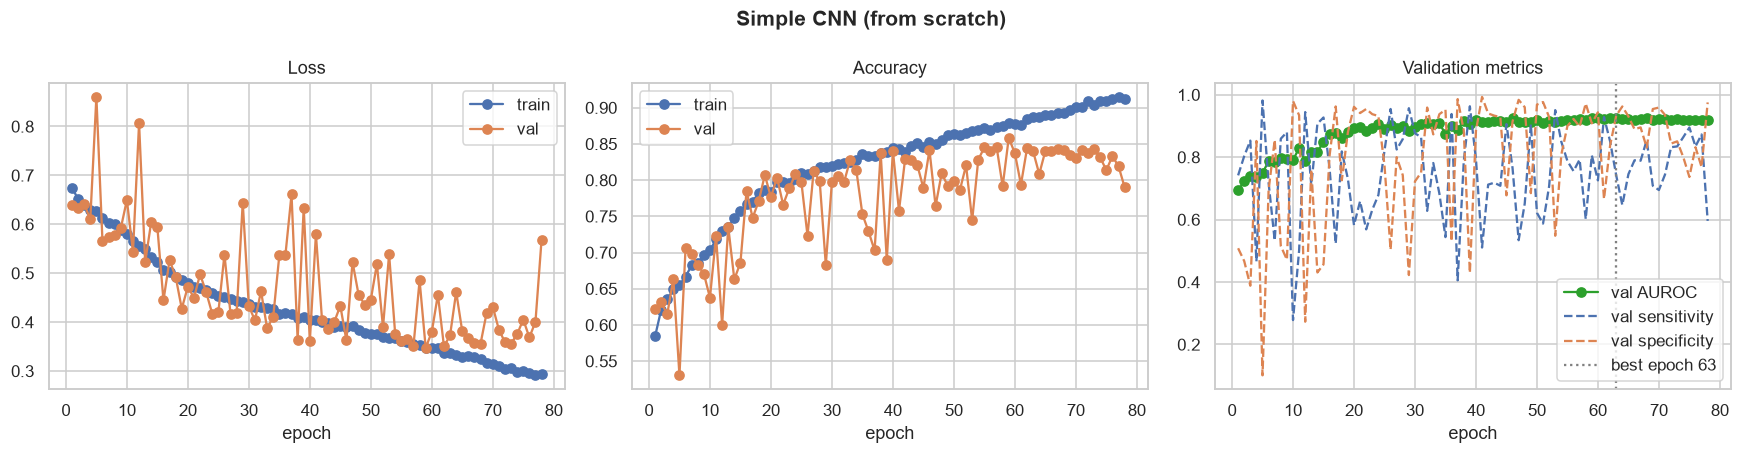

Best epoch 63: val AUROC 0.9257, acc 0.840, sens 0.742, spec 0.933


In [7]:
plot_history(history, "Simple CNN (from scratch)")
plt.savefig(RUN_DIR / "learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()
best = max(history, key=lambda h: h["val_auroc"])
print(f"Best epoch {best['epoch']}: val AUROC {best['val_auroc']:.4f}, acc {best['val_acc']:.3f}, "
      f"sens {best['val_sensitivity']:.3f}, spec {best['val_specificity']:.3f}")
summary = {"arch": "simple_cnn", "parameters": count(model), "best_epoch": best["epoch"],
           "best_val_auroc": best["val_auroc"], "train_minutes": train_minutes, "epochs_run": len(history)}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
del model, optimizer; torch.cuda.empty_cache()